In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

import os
import json
import joblib

In [2]:
data = pd.read_csv("building_database_training_final.csv")

In [3]:
df_energy_gas = data[data['heat_system_type'] == 'gas_boiler'].reset_index(drop=True)
df_energy_elec_heat = data[data['heat_system_type'] == 'heat_pump'].reset_index(drop=True)
df_energy_distrheat = data[data['heat_system_type'] == 'district_heating'].reset_index(drop=True)
df_energy_elec_cool = data[data['cool_system_type'] == 'dx_airco'].reset_index(drop=True)
print(len(df_energy_gas),len(df_energy_elec_heat), len(df_energy_distrheat), len(df_energy_elec_cool))

29240 29240 29240 58480


In [6]:
df_energy_gas['demand/eff'] = df_energy_gas['heating_dem_m2']/df_energy_gas['boiler_eff']
df_energy_elec_heat['demand/cop'] = df_energy_elec_heat['heating_dem_m2']/df_energy_elec_heat['hp_cop']
df_energy_elec_cool['demand/cop'] = df_energy_elec_cool['cooling_dem_m2']/df_energy_elec_cool['dx_cop']

In [7]:
# Finding coefficients based on the general linear model

# Gas consumption
x_gas = df_energy_gas[['demand/eff']].reset_index(drop=True)
y_gas = df_energy_gas['Heating:NaturalGas'].reset_index(drop=True)
b_gas = np.linalg.inv(x_gas.transpose() @ x_gas) @ x_gas.transpose()@y_gas
b_gas = pd.Series(b_gas.to_numpy(), index=x_gas.columns)

# Electricity consumption for heating
x_elec_heat = df_energy_elec_heat[['demand/cop']].reset_index(drop=True)
y_elec_heat = df_energy_elec_heat['Heating:Electricity'].reset_index(drop=True)
b_elec_heat = np.linalg.inv(x_elec_heat.transpose() @ x_elec_heat) @ x_elec_heat.transpose()@y_elec_heat
b_elec_heat = pd.Series(b_elec_heat.to_numpy(), index=x_elec_heat.columns)

# District heating
x_distrheat = df_energy_distrheat[['heating_dem_m2']].reset_index(drop=True)
y_distrheat = df_energy_distrheat['Heating:DistrictHeatingWater'].reset_index(drop=True)
b_distrheat = np.linalg.inv(x_distrheat.transpose() @ x_distrheat) @ x_distrheat.transpose()@y_distrheat
b_distrheat = pd.Series(b_distrheat.to_numpy(), index=x_distrheat.columns)

In [8]:
# Polynomial regression for electricity consumption for cooling
x_elec_cool = df_energy_elec_cool[['demand/cop']].reset_index(drop=True)
y_elec_cool = df_energy_elec_cool['Cooling:Electricity'].reset_index(drop=True)

model3 = make_pipeline(PolynomialFeatures(degree=3), LinearRegression())
model3.fit(x_elec_cool, y_elec_cool)

,steps,"[('polynomialfeatures', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,degree,3
,interaction_only,False
,include_bias,True
,order,'C'
,fit_intercept,True
,copy_X,True
,tol,1e-06


In [9]:
#Predictions
y_pred_gas = x_gas @ b_gas
y_pred_elec_heat = x_elec_heat @ b_elec_heat
y_pred_distrheat = x_distrheat @ b_distrheat

y_pred_elec_cool3 = model3.predict(x_elec_cool)

In [10]:
mape_gas = np.abs((y_pred_gas-y_gas)/y_gas)*100
mape_elec_heat = np.abs((y_pred_elec_heat-y_elec_heat)/y_elec_heat)*100
mape_distrheat = np.abs((y_pred_distrheat-y_distrheat)/y_distrheat)*100
mape_elec_cool = np.abs((y_pred_elec_cool3-y_elec_cool)/y_elec_cool)*100

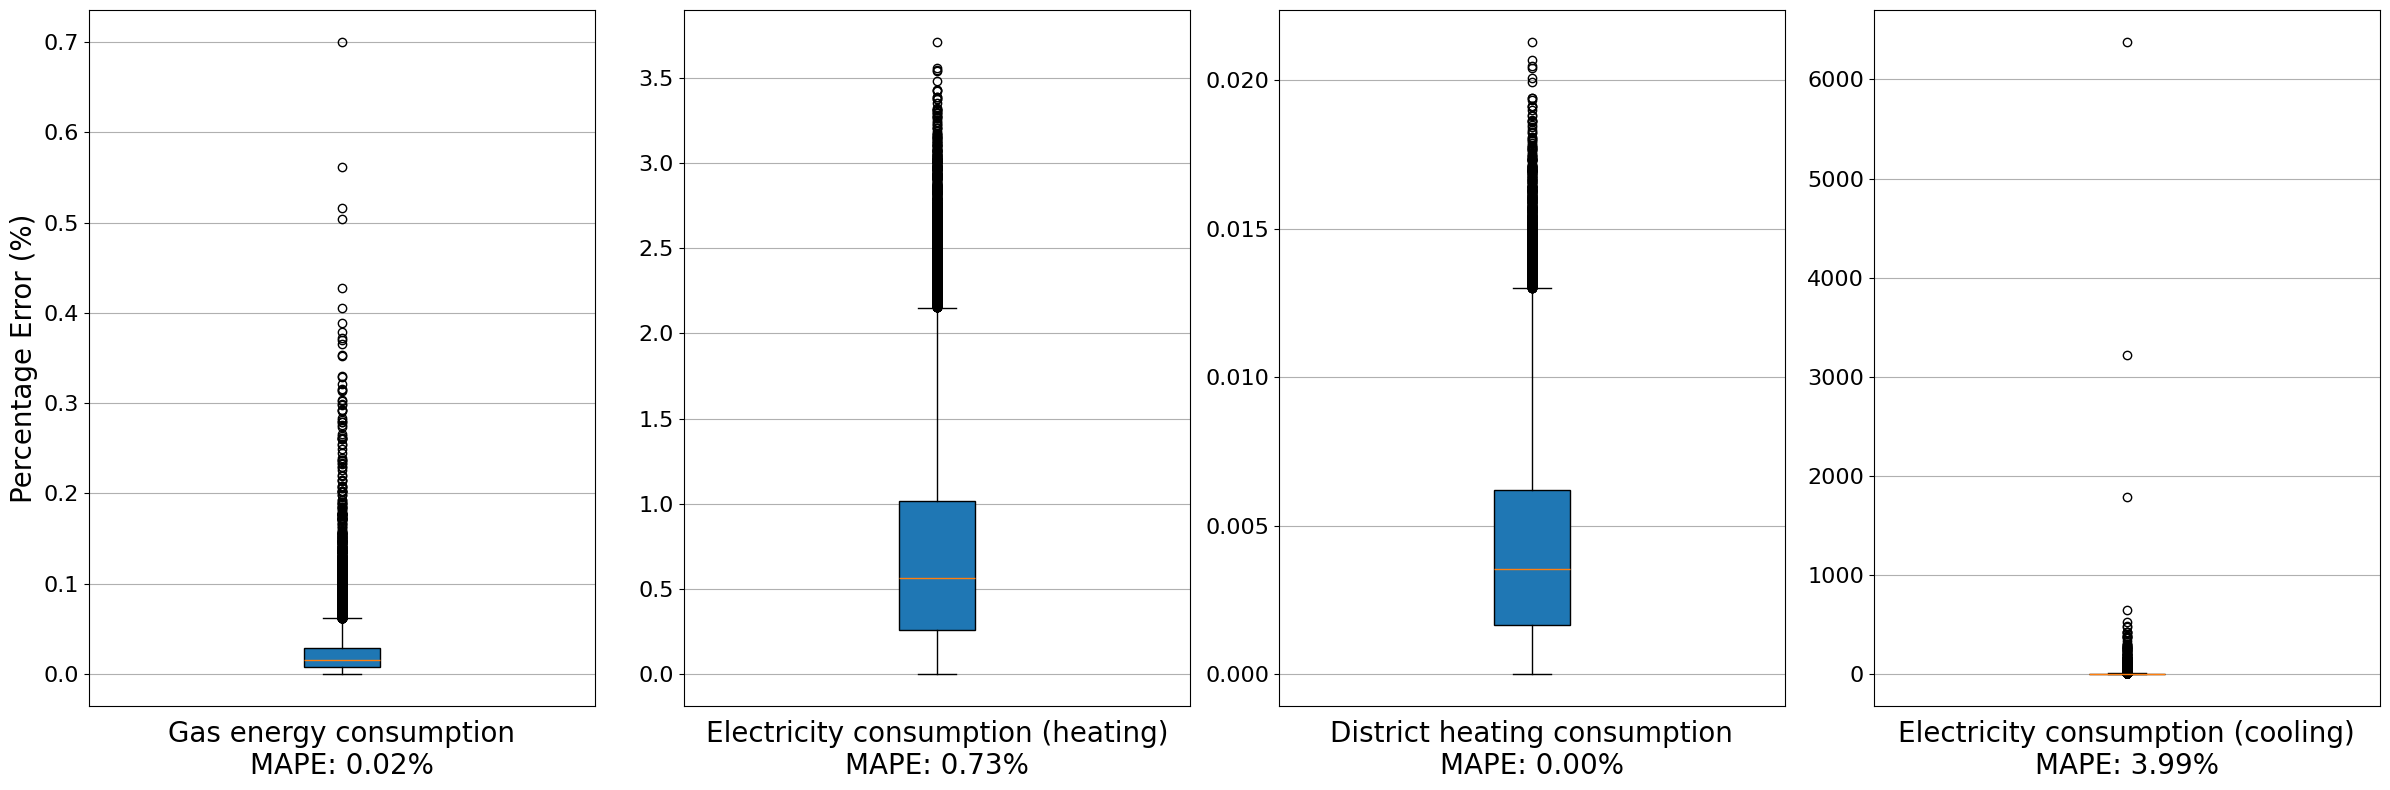

In [ ]:
plt.figure(figsize=(24, 8))

plt.subplot(1, 4, 1)
plt.boxplot(mape_gas, vert=True, patch_artist=True)
plt.xlabel('Gas energy consumption\nMAPE: {:.2f}%'.format(np.mean(mape_gas)), fontsize=20, labelpad=10)
plt.ylabel('Percentage Error (%)', fontsize=20)
plt.tick_params(axis='y', labelsize=16)
plt.xticks([])
plt.grid(axis='y')

plt.subplot(1, 4, 2)
plt.boxplot(mape_elec_heat, vert=True, patch_artist=True)
plt.xlabel('Electricity consumption (heating)\nMAPE: {:.2f}%'.format(np.mean(mape_elec_heat)), fontsize=20, labelpad=10)
plt.ylabel('')
plt.tick_params(axis='y', labelsize=16)
plt.xticks([])
plt.grid(axis='y')

plt.subplot(1, 4, 3)
plt.boxplot(mape_distrheat, vert=True, patch_artist=True)
plt.xlabel('District heating consumption\nMAPE: {:.2f}%'.format(np.mean(mape_distrheat)), fontsize=20, labelpad=10)
plt.ylabel('')
plt.tick_params(axis='y', labelsize=16)
plt.xticks([])
plt.grid(axis='y')

plt.subplot(1, 4, 4)
plt.boxplot(mape_elec_cool, vert=True, patch_artist=True)
plt.xlabel('Electricity consumption (cooling)\nMAPE: {:.2f}%'.format(np.mean(mape_elec_cool)), fontsize=20, labelpad=10)
plt.ylabel('')
plt.tick_params(axis='y', labelsize=16)
plt.xticks([])
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [ ]:
# Save model3 + metadata for X and y


save_dir = 'OUT_models'
os.makedirs(save_dir, exist_ok=True)

model3_path = os.path.join(save_dir, 'model_poly3_elec_cool_reg.joblib')
metadata_path = os.path.join(save_dir, 'model_poly3_elec_cool_reg_metadata.json')

# Save sklearn pipeline
joblib.dump(model3, model3_path)

# Save metadata needed to reuse the model safely
metadata = {
    'model_file': os.path.basename(model3_path),
    'model_type': 'sklearn_pipeline',
    'pipeline': ['PolynomialFeatures(degree=3)', 'LinearRegression()'],
    'x_columns': x_elec_cool.columns.tolist(),
    'y_name': y_elec_cool.name,
    'x_shape': list(x_elec_cool.shape),
    'y_shape': list(y_elec_cool.shape),
    'n_samples': int(len(x_elec_cool))
}

with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)

print(f"Saved model to: {model3_path}")
print(f"Saved metadata to: {metadata_path}")

# Example reload
# loaded_model3 = joblib.load(model3_path)
# with open(metadata_path, 'r', encoding='utf-8') as f:
#     loaded_metadata = json.load(f)
# print(loaded_metadata)
# y_pred_loaded = loaded_model3.predict(x_elec_cool[loaded_metadata['x_columns']])

Saved model to: OUT_models\model_poly3_elec_cool_reg.joblib
Saved metadata to: OUT_models\model_poly3_elec_cool_reg_metadata.json


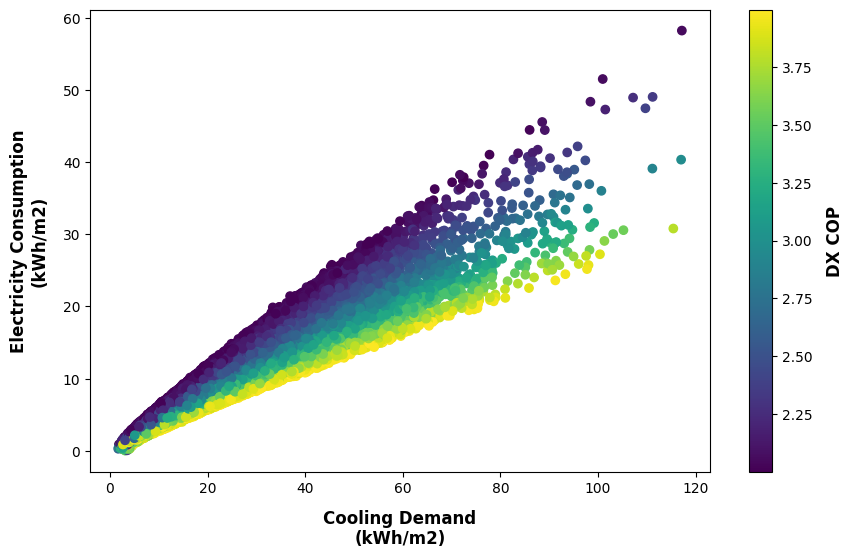

In [25]:
plt.figure(figsize=(10, 6))
sc=plt.scatter(df_energy_elec_cool['cooling_dem_m2'], 
            df_energy_elec_cool['Cooling:Electricity'],
            c=df_energy_elec_cool['dx_cop'], cmap='viridis')

plt.xlabel('Cooling Demand\n(kWh/m2)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Electricity Consumption\n(kWh/m2)', fontsize=12, fontweight='bold', labelpad=10)
cbar=plt.colorbar(sc)  # shows color scale
cbar.set_label('DX COP', fontsize=12, labelpad=10, fontweight='bold')  # sets colorbar label
cbar.ax.tick_params(labelsize=10)  # sets colorbar tick label size
plt.show()

In [27]:
# Fit different models for comparison
b_elec_cool = np.linalg.inv(x_elec_cool.transpose() @ x_elec_cool) @ x_elec_cool.transpose()@y_elec_cool
b_elec_cool = pd.Series(b_elec_cool.to_numpy(), index=x_elec_cool.columns)

model2 = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
model2.fit(x_elec_cool, y_elec_cool)

model4 = make_pipeline(PolynomialFeatures(degree=4), LinearRegression())
model4.fit(x_elec_cool, y_elec_cool)

model5 = make_pipeline(PolynomialFeatures(degree=5), LinearRegression())
model5.fit(x_elec_cool, y_elec_cool)

,steps,"[('polynomialfeatures', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,degree,5
,interaction_only,False
,include_bias,True
,order,'C'
,fit_intercept,True
,copy_X,True
,tol,1e-06


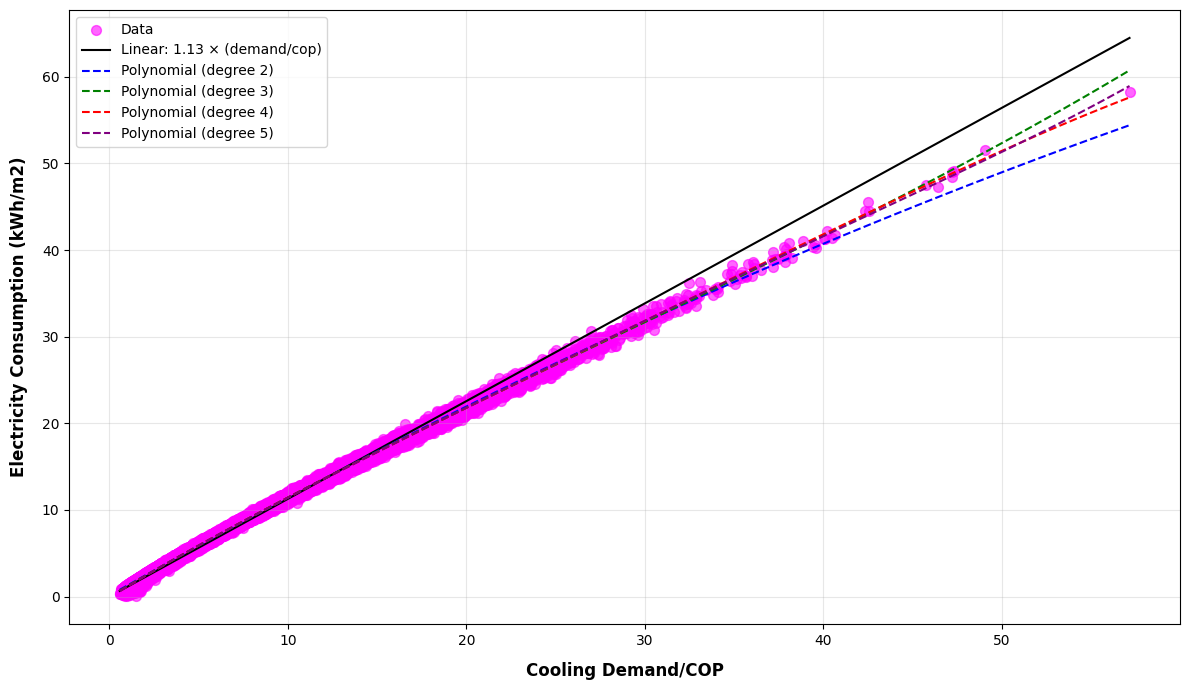

In [28]:
# Plot prediction lines over the data
plt.figure(figsize=(12, 7))
sc = plt.scatter(
    df_energy_elec_cool['demand/cop'],
    df_energy_elec_cool['Cooling:Electricity'],
    color="magenta",
    alpha=0.6,
    s=50,
    label='Data'
)

x_line = np.linspace(
    df_energy_elec_cool['demand/cop'].min(),
    df_energy_elec_cool['demand/cop'].max(),
    100
)
x_line_df = pd.DataFrame({'demand/cop': x_line})

# Linear regression line
y_line = b_elec_cool['demand/cop'] * x_line
plt.plot(
    x_line,
    y_line,
    color='black',
    linewidth=1.5,
    label=f"Linear: {b_elec_cool['demand/cop']:.2f} × (demand/cop)"
)

# Polynomial regression lines
y_line_2 = model2.predict(x_line_df)
plt.plot(x_line, y_line_2, color='blue', linewidth=1.5, linestyle='--', label='Polynomial (degree 2)')

y_line_3 = model3.predict(x_line_df)
plt.plot(x_line, y_line_3, color='green', linewidth=1.5, linestyle='--', label='Polynomial (degree 3)')

y_line_4 = model4.predict(x_line_df)
plt.plot(x_line, y_line_4, color='red', linewidth=1.5, linestyle='--', label='Polynomial (degree 4)')

y_line_5 = model5.predict(x_line_df)
plt.plot(x_line, y_line_5, color='purple', linewidth=1.5, linestyle='--', label='Polynomial (degree 5)')

plt.xlabel('Cooling Demand/COP', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Electricity Consumption (kWh/m2)', fontsize=12, fontweight='bold', labelpad=10)
plt.legend(fontsize=10, loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
